In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

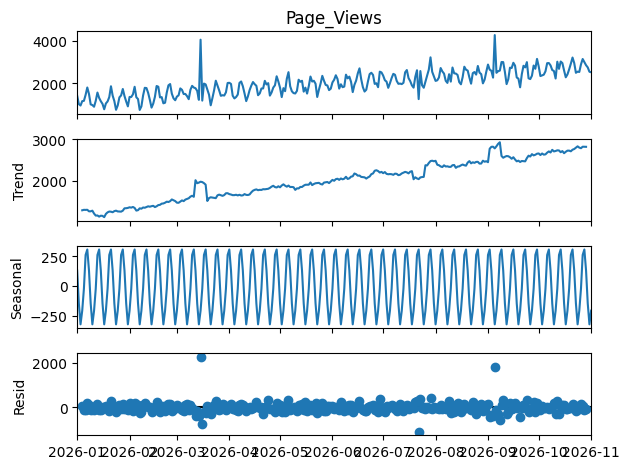

In [2]:
# Setting a random seed for reproducible results
np.random.seed(42)

# Generate a continuous daily timeline for 2026
date_range = pd.date_range(start="2026-01-01", end="2026-11-01", freq="D")

# Build data components: Growth Trend + Weekly Cycles + Random Fluctuations
trend = np.linspace(1200, 2800, len(date_range))
weekly_seasonality = 350 * np.sin(2 * np.pi * date_range.dayofweek / 7)
random_noise = np.random.normal(0, 150, len(date_range))
page_views = trend + weekly_seasonality + random_noise

# Construct the core DataFrame
data = pd.DataFrame({"Page_Views": page_views}, index=date_range)
data.index.name = "Date"

# Inject explicit statistical anomalies (huge traffic spikes/drops)
data.loc["2026-03-15", "Page_Views"] += 2500  # Marketing campaign spike
data.loc["2026-07-22", "Page_Views"] -= 1500  # Server downtime drop
data.loc["2026-09-05", "Page_Views"] += 2200  # Viral post spike


# --- STEP 2: TIME SERIES DECOMPOSITION ---
# period=7 isolates the 7-day weekly traffic cycle
decomposition = seasonal_decompose(data["Page_Views"], model="additive", period=7)
decomposition.plot()
plt.tight_layout()
plt.show()

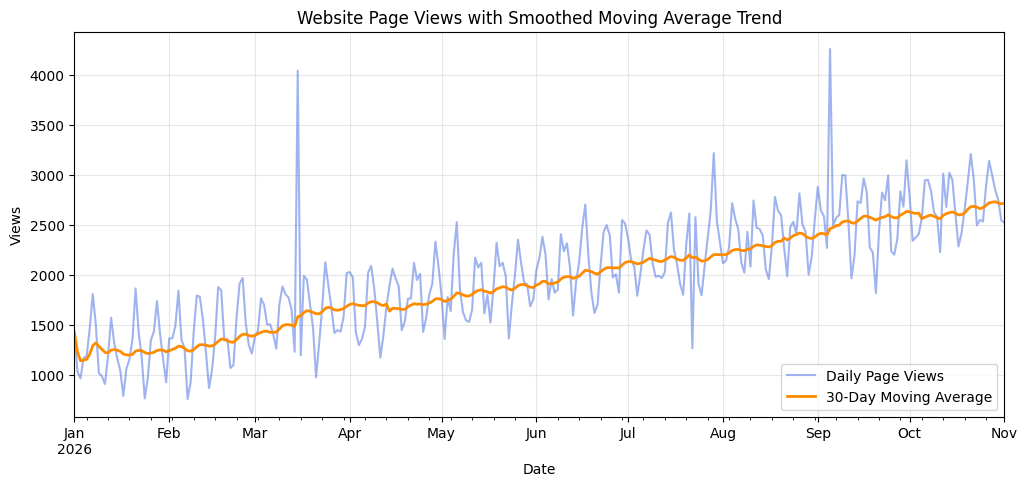

In [3]:
# --- STEP 3: MOVING AVERAGE ---
# min_periods=1 ensures calculation starts immediately instead of returning NaN

data["Page_Views_MA"] = data["Page_Views"].rolling(window=30, min_periods=1).mean()

plt.figure(figsize=(12, 5))
data["Page_Views"].plot(label="Daily Page Views", alpha=0.5, color="royalblue")
data["Page_Views_MA"].plot(label="30-Day Moving Average", color="darkorange", linewidth=2)
plt.title("Website Page Views with Smoothed Moving Average Trend")
plt.ylabel("Views")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

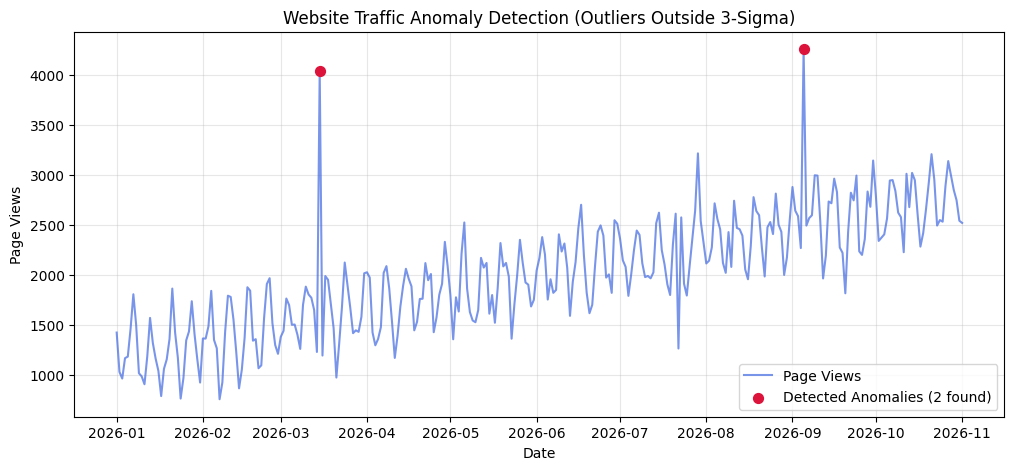

In [4]:
# --- STEP 4: ANOMALY DETECTION ---
# Calculate the Z-score for deviation detection
data["Page_Views_Z"] = (data["Page_Views"] - data["Page_Views"].mean()) / data["Page_Views"].std()

# Flag items that deviate by more than 3 standard deviations
anomalies = data[data["Page_Views_Z"].abs() > 3]

plt.figure(figsize=(12, 5))
plt.plot(data.index, data["Page_Views"], label="Page Views", color="royalblue", alpha=0.7)
plt.scatter(
    anomalies.index,
    anomalies["Page_Views"],
    color="crimson",
    label=f"Detected Anomalies ({len(anomalies)} found)",
    s=50,
    zorder=5,
)
plt.title("Website Traffic Anomaly Detection (Outliers Outside 3-Sigma)")
plt.xlabel("Date")
plt.ylabel("Page Views")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()